# Partie 4 – Analyse de corrélation

Objectif : analyser les corrélations entre différentes variables métier de ClassicModels pour identifier des relations significatives.

Variables à analyser :
- **Prix produit vs quantité vendue** : est-ce que les produits chers se vendent moins ?
- **Délai de livraison vs montant commande** : est-ce que les délais longs impactent le montant des commandes ?
- **Montant commande vs nombre de produits** : relation entre panier moyen et diversité
- **Ancienneté client vs montant total dépensé** : les anciens clients dépensent-ils plus ?
- **Prix achat vs prix vente** : analyse de la marge (MSRP vs buyPrice)
- **Nombre de commandes client vs montant total** : fidélité vs valeur client

In [10]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import fetch_dataframe

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

## Extraction des données pour l'analyse de corrélation

On va extraire plusieurs variables depuis la base de données pour analyser leurs corrélations.

In [12]:
# Requête pour extraire les variables d'intérêt
query_correlation = """
SELECT
    -- Variables produit
    p.productCode,
    p.buyPrice AS prix_achat,
    p.MSRP AS prix_vente,
    
    -- Variables vente
    od.quantityOrdered AS quantite_vendue,
    od.priceEach AS prix_unitaire_vendu,
    (od.quantityOrdered * od.priceEach) AS montant_ligne,
    
    -- Variables commande
    o.orderNumber,
    o.orderDate,
    o.shippedDate,
    o.status,
    DATEDIFF(o.shippedDate, o.orderDate) AS delai_livraison_jours,
    
    -- Variables client
    c.customerNumber,
    c.customerName,
    DATEDIFF(o.orderDate, (SELECT MIN(o2.orderDate) FROM orders o2 WHERE o2.customerNumber = c.customerNumber)) AS anciennete_client_jours,
    (SELECT COUNT(DISTINCT o3.orderNumber) 
     FROM orders o3 
     WHERE o3.customerNumber = c.customerNumber 
       AND o3.status = 'Shipped') AS nb_commandes_client,
    (SELECT SUM(od4.quantityOrdered * od4.priceEach)
     FROM orders o4
     JOIN orderdetails od4 ON od4.orderNumber = o4.orderNumber
     WHERE o4.customerNumber = c.customerNumber 
       AND o4.status = 'Shipped') AS montant_total_client,
    
    -- Variables commande globale
    (SELECT COUNT(DISTINCT od2.productCode) 
     FROM orderdetails od2 
     WHERE od2.orderNumber = o.orderNumber) AS nb_produits_commande,
    
    (SELECT SUM(od3.quantityOrdered * od3.priceEach)
     FROM orderdetails od3
     WHERE od3.orderNumber = o.orderNumber) AS montant_total_commande

FROM products p
JOIN orderdetails od ON od.productCode = p.productCode
JOIN orders o ON o.orderNumber = od.orderNumber
JOIN customers c ON c.customerNumber = o.customerNumber
WHERE o.status = 'Shipped'
  AND o.shippedDate IS NOT NULL
  AND o.orderDate IS NOT NULL
ORDER BY o.orderDate;
"""

df_corr = fetch_dataframe(query_correlation)
print(f"Nombre de lignes extraites : {len(df_corr)}")
df_corr.head()

C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


Nombre de lignes extraites : 2771


,productCode,prix_achat,prix_vente,quantite_vendue,prix_unitaire_vendu,montant_ligne,orderNumber,orderDate,shippedDate,status,delai_livraison_jours,customerNumber,customerName,anciennete_client_jours,nb_commandes_client,montant_total_client,nb_produits_commande,montant_total_commande
0,S18_1749,86.70,170.00,30,136.00,4080.00,10100,2003-01-06,2003-01-10,Shipped,4,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
1,S18_2248,33.30,60.54,50,55.09,2754.50,10100,2003-01-06,2003-01-10,Shipped,4,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
2,S18_4409,43.26,92.03,22,75.46,1660.12,10100,2003-01-06,2003-01-10,Shipped,4,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
3,S24_3969,21.75,41.03,49,35.29,1729.21,10100,2003-01-06,2003-01-10,Shipped,4,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
4,S18_2325,58.48,127.13,25,108.06,2701.50,10101,2003-01-09,2003-01-11,Shipped,2,128,"Blauer See Auto, Co.",0,4,75937.76,4,10549.01


In [13]:
# Vérification des valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df_corr.isnull().sum())
print("\nTypes de données :")
print(df_corr.dtypes)

# Conversion des dates
df_corr["orderDate"] = pd.to_datetime(df_corr["orderDate"])
df_corr["shippedDate"] = pd.to_datetime(df_corr["shippedDate"])

# Vérification des valeurs aberrantes pour delai_livraison
print("\nStatistiques sur le délai de livraison :")
print(df_corr["delai_livraison_jours"].describe())

Valeurs manquantes par colonne :
productCode                0
prix_achat                 0
prix_vente                 0
quantite_vendue            0
prix_unitaire_vendu        0
montant_ligne              0
orderNumber                0
orderDate                  0
shippedDate                0
status                     0
delai_livraison_jours      0
customerNumber             0
customerName               0
anciennete_client_jours    0
nb_commandes_client        0
montant_total_client       0
nb_produits_commande       0
montant_total_commande     0
dtype: int64

Types de données :
productCode                    str
prix_achat                 float64
prix_vente                 float64
quantite_vendue              int64
prix_unitaire_vendu        float64
montant_ligne              float64
orderNumber                  int64
orderDate                   object
shippedDate                 object
status                         str
delai_livraison_jours        int64
customerNumber             

## Calcul de la matrice de corrélation

On calcule les corrélations entre les variables numériques d'intérêt.

In [15]:
# Sélection des variables numériques pour la corrélation
variables_correlation = [
    "prix_achat",
    "prix_vente",
    "prix_unitaire_vendu",
    "quantite_vendue",
    "montant_ligne",
    "delai_livraison_jours",
    "anciennete_client_jours",
    "nb_commandes_client",
    "montant_total_client",
    "nb_produits_commande",
    "montant_total_commande"
]

# Création d'un DataFrame avec uniquement les variables numériques
df_corr_numeric = df_corr[variables_correlation].copy()

# Suppression des valeurs aberrantes (délai de livraison négatif ou très élevé)
df_corr_numeric = df_corr_numeric[
    (df_corr_numeric["delai_livraison_jours"] >= 0) & 
    (df_corr_numeric["delai_livraison_jours"] <= 365)
]

# Calcul de la matrice de corrélation
correlation_matrix = df_corr_numeric.corr()

print("Matrice de corrélation :")
print(correlation_matrix.round(3))

Matrice de corrélation :
                         prix_achat  prix_vente  prix_unitaire_vendu  \
prix_achat                    1.000       0.919                0.905   
prix_vente                    0.919       1.000                0.983   
prix_unitaire_vendu           0.905       0.983                1.000   
quantite_vendue               0.027       0.020                0.023   
montant_ligne                 0.736       0.794                0.811   
delai_livraison_jours         0.017       0.019                0.014   
anciennete_client_jours       0.018       0.015                0.012   
nb_commandes_client           0.000      -0.007               -0.007   
montant_total_client          0.004      -0.002               -0.002   
nb_produits_commande         -0.023      -0.033               -0.033   
montant_total_commande        0.064       0.057                0.058   

                         quantite_vendue  montant_ligne  \
prix_achat                         0.027          0

## Visualisation : Heatmap de corrélation

Création d'un heatmap pour visualiser visuellement les corrélations entre toutes les variables.

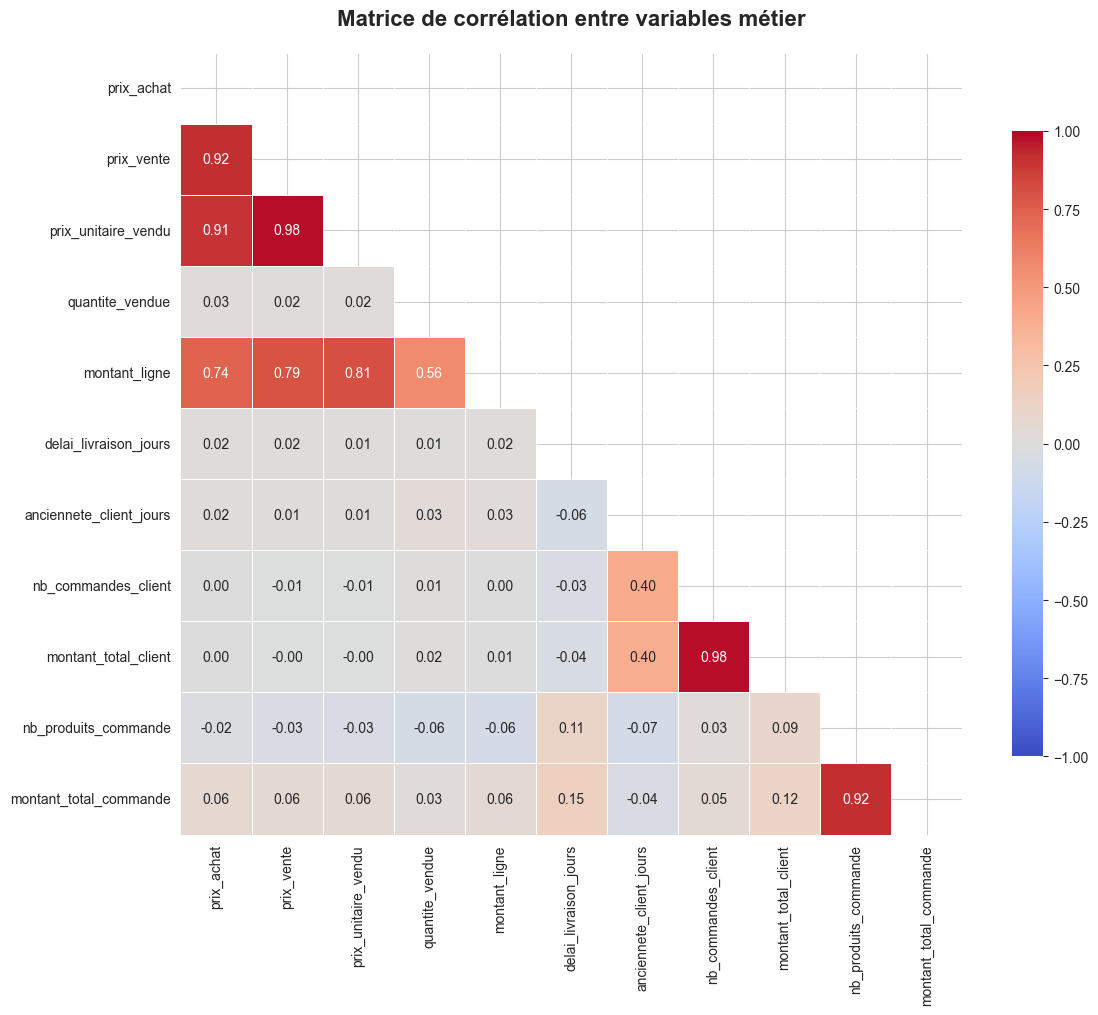

In [16]:
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation entre variables métier", fontsize=16, fontweight="bold", pad=20)
plt.tight_layout()
plt.show()

## Analyse des corrélations spécifiques

Analyse détaillée des corrélations les plus intéressantes.

In [17]:
# Corrélations les plus fortes (positives et négatives)
correlations_flat = correlation_matrix.unstack()
correlations_flat = correlations_flat[correlations_flat.index.get_level_values(0) != correlations_flat.index.get_level_values(1)]
correlations_flat = correlations_flat.sort_values(ascending=False)

print("Top 10 corrélations positives les plus fortes :")
print(correlations_flat.head(10))
print("\nTop 10 corrélations négatives les plus fortes :")
print(correlations_flat.tail(10))

Top 10 corrélations positives les plus fortes :
montant_total_client    nb_commandes_client       0.984182
nb_commandes_client     montant_total_client      0.984182
prix_vente              prix_unitaire_vendu       0.983111
prix_unitaire_vendu     prix_vente                0.983111
prix_vente              prix_achat                0.919214
prix_achat              prix_vente                0.919214
montant_total_commande  nb_produits_commande      0.915461
nb_produits_commande    montant_total_commande    0.915461
prix_unitaire_vendu     prix_achat                0.905219
prix_achat              prix_unitaire_vendu       0.905219
dtype: float64

Top 10 corrélations négatives les plus fortes :
montant_total_client     delai_livraison_jours     -0.040129
delai_livraison_jours    montant_total_client      -0.040129
                         anciennete_client_jours   -0.059468
anciennete_client_jours  delai_livraison_jours     -0.059468
quantite_vendue          nb_produits_commande      -0.

## Visualisations des corrélations spécifiques

Graphiques pour visualiser les relations entre variables clés.

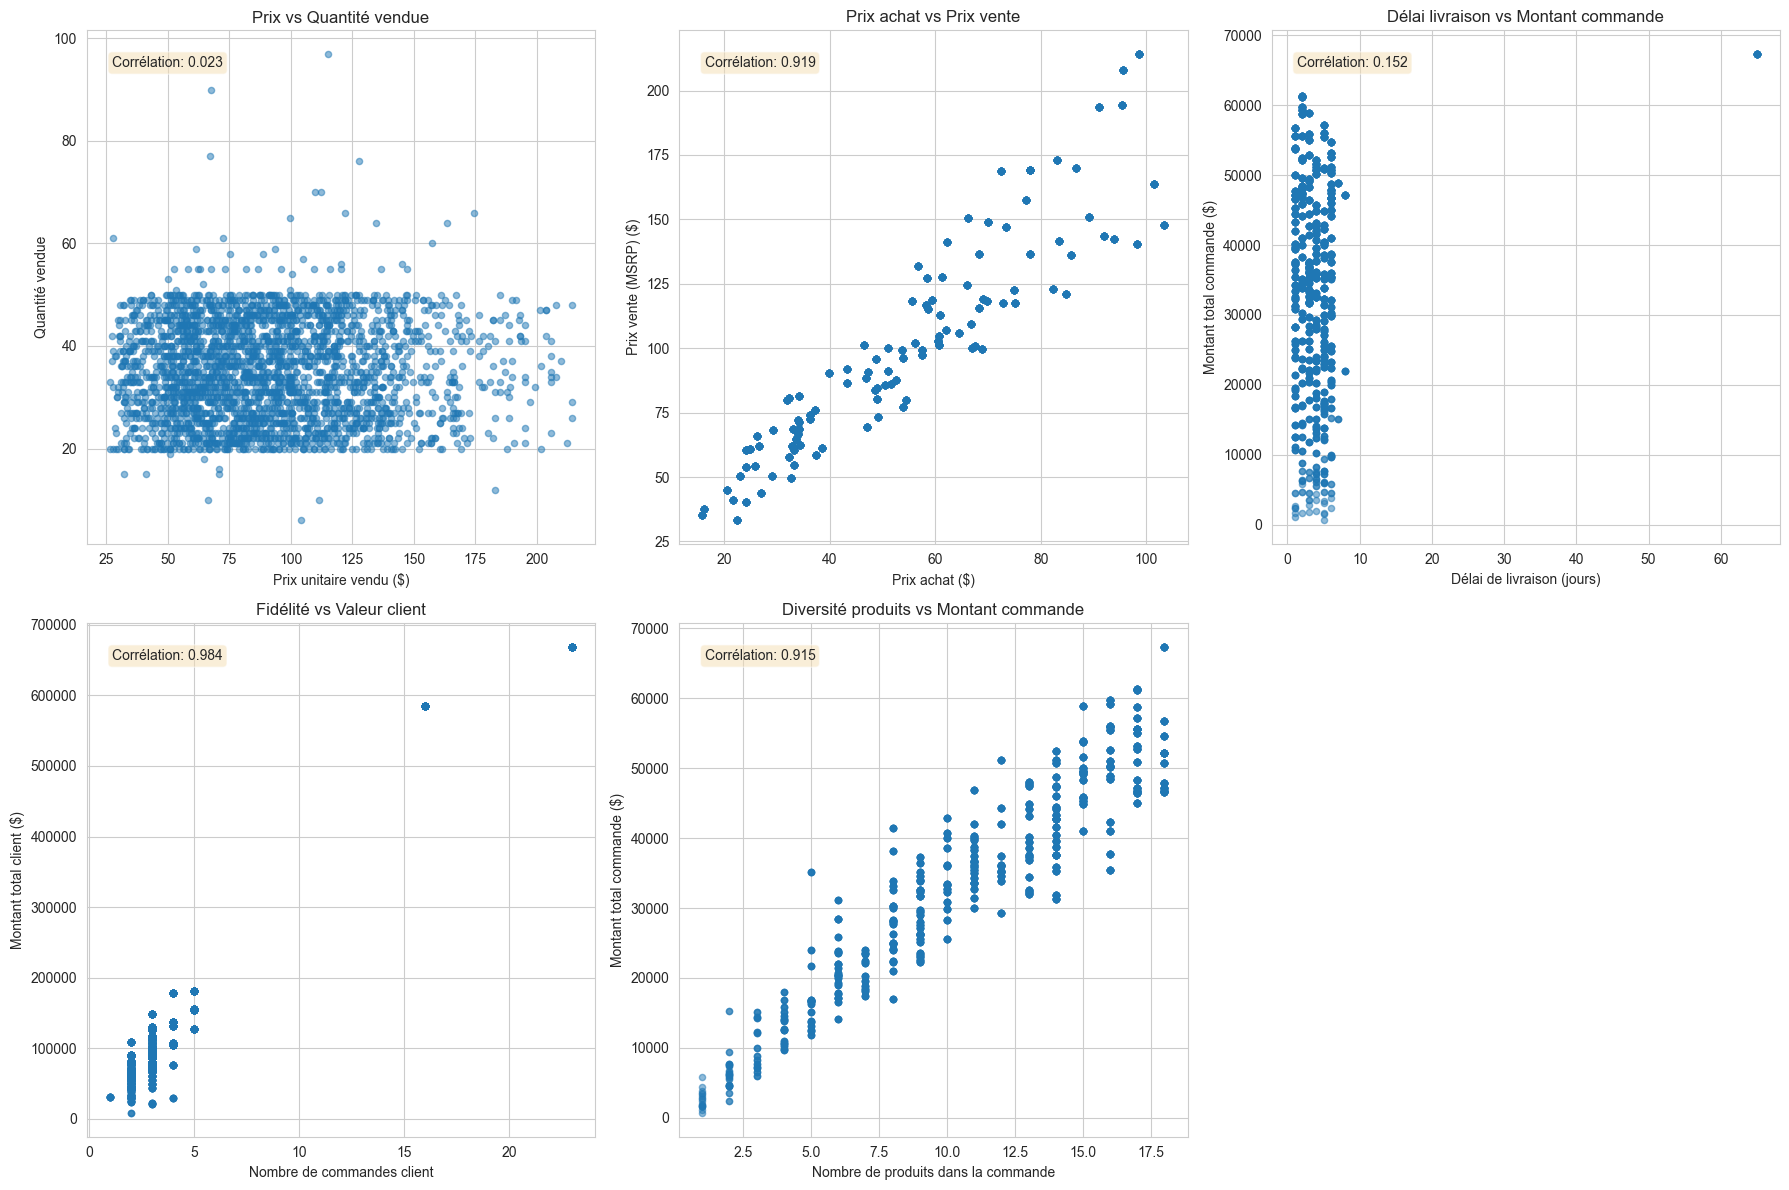

In [21]:
# Échantillonnage pour améliorer la performance des graphiques
df_sample = df_corr_numeric.sample(n=min(5000, len(df_corr_numeric)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Prix vs Quantité vendue
axes[0, 0].scatter(df_sample["prix_unitaire_vendu"], df_sample["quantite_vendue"], alpha=0.5, s=20)
axes[0, 0].set_xlabel("Prix unitaire vendu ($)")
axes[0, 0].set_ylabel("Quantité vendue")
axes[0, 0].set_title("Prix vs Quantité vendue")
corr_price_qty = df_corr_numeric["prix_unitaire_vendu"].corr(df_corr_numeric["quantite_vendue"])
axes[0, 0].text(0.05, 0.95, f"Corrélation: {corr_price_qty:.3f}", transform=axes[0, 0].transAxes, 
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 2. Prix achat vs Prix vente (marge)
axes[0, 1].scatter(df_sample["prix_achat"], df_sample["prix_vente"], alpha=0.5, s=20)
axes[0, 1].set_xlabel("Prix achat ($)")
axes[0, 1].set_ylabel("Prix vente (MSRP) ($)")
axes[0, 1].set_title("Prix achat vs Prix vente")
corr_buy_msrp = df_corr_numeric["prix_achat"].corr(df_corr_numeric["prix_vente"])
axes[0, 1].text(0.05, 0.95, f"Corrélation: {corr_buy_msrp:.3f}", transform=axes[0, 1].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 3. Délai livraison vs Montant commande
axes[0, 2].scatter(df_sample["delai_livraison_jours"], df_sample["montant_total_commande"], alpha=0.5, s=20)
axes[0, 2].set_xlabel("Délai de livraison (jours)")
axes[0, 2].set_ylabel("Montant total commande ($)")
axes[0, 2].set_title("Délai livraison vs Montant commande")
corr_delay_amount = df_corr_numeric["delai_livraison_jours"].corr(df_corr_numeric["montant_total_commande"])
axes[0, 2].text(0.05, 0.95, f"Corrélation: {corr_delay_amount:.3f}", transform=axes[0, 2].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 4. Nombre commandes vs Montant total client (fidélité)
axes[1, 0].scatter(df_sample["nb_commandes_client"], df_sample["montant_total_client"], alpha=0.5, s=20)
axes[1, 0].set_xlabel("Nombre de commandes client")
axes[1, 0].set_ylabel("Montant total client ($)")
axes[1, 0].set_title("Fidélité vs Valeur client")
corr_nb_orders_amount = df_corr_numeric["nb_commandes_client"].corr(df_corr_numeric["montant_total_client"])
axes[1, 0].text(0.05, 0.95, f"Corrélation: {corr_nb_orders_amount:.3f}", transform=axes[1, 0].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 5. Nombre produits vs Montant commande
axes[1, 1].scatter(df_sample["nb_produits_commande"], df_sample["montant_total_commande"], alpha=0.5, s=20)
axes[1, 1].set_xlabel("Nombre de produits dans la commande")
axes[1, 1].set_ylabel("Montant total commande ($)")
axes[1, 1].set_title("Diversité produits vs Montant commande")
corr_nb_amount = df_corr_numeric["nb_produits_commande"].corr(df_corr_numeric["montant_total_commande"])
axes[1, 1].text(0.05, 0.95, f"Corrélation: {corr_nb_amount:.3f}", transform=axes[1, 1].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Masquer le dernier subplot (vide)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

In [22]:
# Tableau récapitulatif des corrélations clés
key_correlations = pd.DataFrame({
    "Variable 1": ["Prix unitaire", "Prix achat", "Délai livraison", "Nb commandes", "Nombre produits"],
    "Variable 2": ["Quantité vendue", "Prix vente (MSRP)", "Montant commande", "Montant total client", "Montant commande"],
    "Corrélation": [
        df_corr_numeric["prix_unitaire_vendu"].corr(df_corr_numeric["quantite_vendue"]),
        df_corr_numeric["prix_achat"].corr(df_corr_numeric["prix_vente"]),
        df_corr_numeric["delai_livraison_jours"].corr(df_corr_numeric["montant_total_commande"]),
        df_corr_numeric["nb_commandes_client"].corr(df_corr_numeric["montant_total_client"]),
        df_corr_numeric["nb_produits_commande"].corr(df_corr_numeric["montant_total_commande"])
    ]
})

key_correlations["Interprétation"] = key_correlations["Corrélation"].apply(
    lambda x: "Forte positive" if x > 0.5 else "Modérée positive" if x > 0.2 else 
              "Forte négative" if x < -0.5 else "Modérée négative" if x < -0.2 else "Faible"
)

print("Résumé des corrélations clés :\n")
display(key_correlations.round(3))

Résumé des corrélations clés :



,Variable 1,Variable 2,Corrélation,Interprétation
0,Prix unitaire,Quantité vendue,0.023,Faible
1,Prix achat,Prix vente (MSRP),0.919,Forte positive
2,Délai livraison,Montant commande,0.152,Faible
3,Nb commandes,Montant total client,0.984,Forte positive
4,Nombre produits,Montant commande,0.915,Forte positive
